# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
#Estadísticas originales
print("Originales:")
print(data.describe())

#Estadísticas después de MinMaxScaler
print("\nMinMax:")
print(data_minmax.describe())

Originales:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  

MinMax:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            0.428704     

En MinMax todas las columnas quedan con mínimo 0 y máximo 1. En los datos originales cada columna tiene su propio rango (por ejemplo, petal length va de 1.0 a 6.9 y sepal width de 2.0 a 4.4).

La media queda entre 0 y 1 y la desviación estándar se reduce, porque los datos se comprimen al intervalo [0, 1].

Los datos mantienen sus posiciones relativas, la forma y distribución no cambia, solo la escala.

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

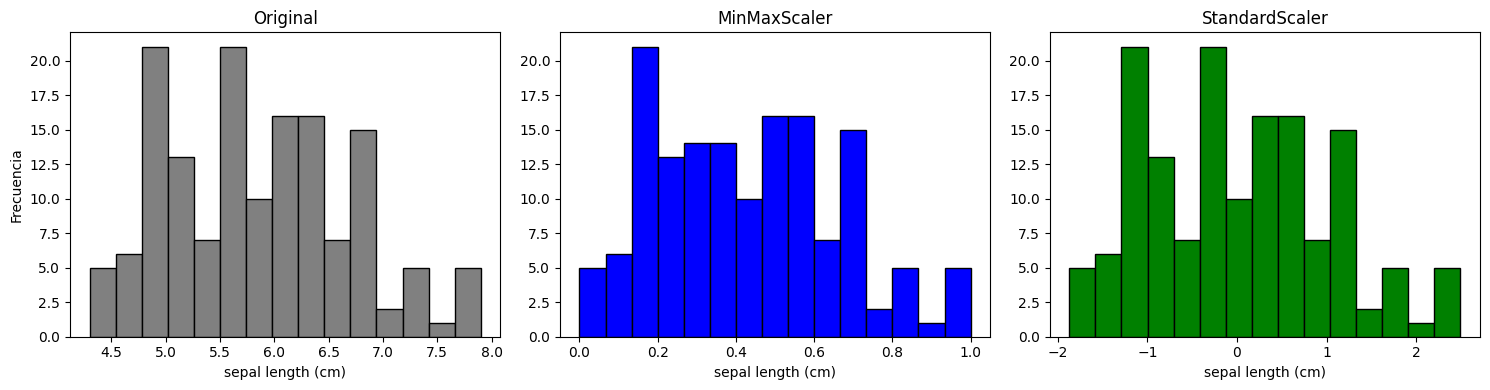

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(data['sepal length (cm)'], bins=15, color='gray', edgecolor='black')
axes[0].set_title('Original')
axes[0].set_xlabel('sepal length (cm)')
axes[0].set_ylabel('Frecuencia')

axes[1].hist(data_minmax['sepal length (cm)'], bins=15, color='blue', edgecolor='black')
axes[1].set_title('MinMaxScaler')
axes[1].set_xlabel('sepal length (cm)')

axes[2].hist(data_standard['sepal length (cm)'], bins=15, color='green', edgecolor='black')
axes[2].set_title('StandardScaler')
axes[2].set_xlabel('sepal length (cm)')

plt.tight_layout()
plt.show()

Se usaron los escalados MinMaxScaler (azul: data_minmax) y StandardScaler (verde: data_standard) y se mantuvo el Original en gris.

Las tres gráficas tienen la misma forma. Lo único que cambia es el eje x: de 4.3-7.9 (original) a 0-1 (MinMax) y a aproximadamente -2 a 2.5 (Standard).

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

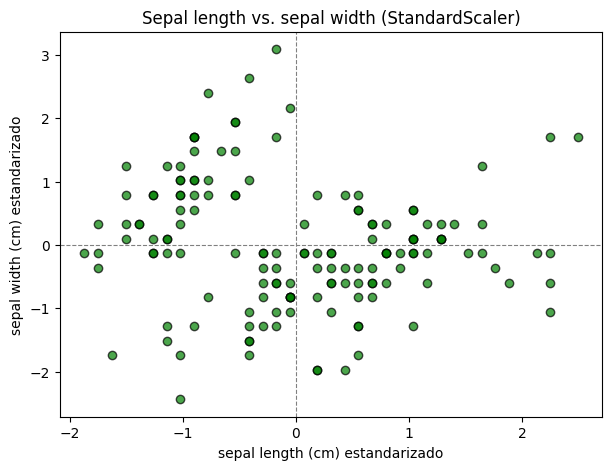

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(data_standard['sepal length (cm)'],
            data_standard['sepal width (cm)'],
            color='green', edgecolor='black', alpha=0.7)

plt.title('Sepal length vs. sepal width (StandardScaler)')
plt.xlabel('sepal length (cm) estandarizado')
plt.ylabel('sepal width (cm) estandarizado')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.show()

En la gráfica de dispersión con StandardScaler, los datos se centran en el origen (0, 0), que representa la media de cada variable. 
Cada punto indica cuántas desviaciones estándar se aleja de la media en sepal length y sepal width, es decir la relacion de cada flor con el promedio. Ambas variables quedan en la misma escala, lo que permite comparar las flores directamente sin que una domine por tener valores numéricos más grandes. La forma de la nube de puntos se conserva, ya que el escalado no altera las relaciones entre variables.

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

In [9]:
print(data_minmax.describe().loc[['min', 'max']])
print(data_standard.describe().loc[['mean', 'std']].round(2))

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
min                0.0               0.0                0.0               0.0
max                1.0               1.0                1.0               1.0
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean               -0.0              -0.0               -0.0              -0.0
std                 1.0               1.0                1.0               1.0


Para el conjunto de datos iris considero que StandardScaler es la técnica más adecuada. 

Las cuatro variables están medidas en centímetros pero con rangos y dispersiones distintas, y StandardScaler las deja con media 0 y desviación estándar 1 (como se comprobó en la salida), lo que permite compararlas en igualdad de condiciones. Además, es la opción preferida para algoritmos sensibles a la escala, como KNN, SVM o regresión logística. 

MinMaxScaler también sería válido, ya que iris no tiene valores atípicos marcados, pero depende del mínimo y el máximo, por lo que un solo outlier podría comprimir el resto de los datos.